<a href="https://colab.research.google.com/github/Sibuninja/ML_LAB_ASSIGNMENT/blob/ASSIGNMENT-3/EM_ALOGORITHM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from scipy.stats import multivariate_normal
from matplotlib.patches import Ellipse

print("Libraries imported successfully!")

Libraries imported successfully!


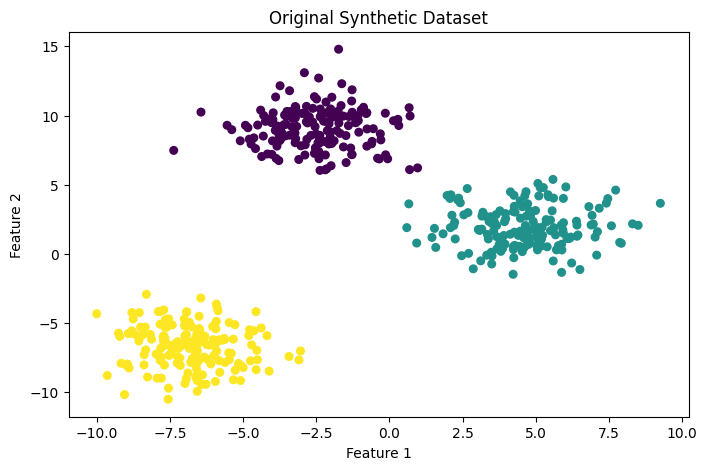

Dataset Shape: (500, 2)


In [25]:
X, y = make_blobs(
    n_samples=500,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=30)

plt.title("Original Synthetic Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Dataset Shape:", X.shape)

In [26]:
N, D = X.shape
K = 3

np.random.seed(42)

# Initialize means
indices = np.random.choice(N, K, replace=False)
means = X[indices].copy()

# Initialize covariance matrices
covariances = np.array([np.eye(D) for _ in range(K)])

# Initialize weights
weights = np.ones(K) / K

print("Initial Means:\n", means)
print("\nInitial Covariances:\n", covariances)
print("\nInitial Weights:\n", weights)

Initial Means:
 [[-3.32577171  9.18067001]
 [-6.68747057 -7.90168708]
 [-7.74308393 -6.69709487]]

Initial Covariances:
 [[[1. 0.]
  [0. 1.]]

 [[1. 0.]
  [0. 1.]]

 [[1. 0.]
  [0. 1.]]]

Initial Weights:
 [0.33333333 0.33333333 0.33333333]


In [27]:
def e_step(X, means, covariances, weights):

    N = X.shape[0]
    K = len(weights)

    responsibilities = np.zeros((N, K))

    for k in range(K):

        responsibilities[:, k] = (
            weights[k] *
            multivariate_normal.pdf(
                X,
                mean=means[k],
                cov=covariances[k],
                allow_singular=True
            )
        )

    # Normalize probabilities
    responsibilities /= (
        responsibilities.sum(axis=1, keepdims=True) + 1e-10
    )

    return responsibilities

print("E-Step function defined successfully!")

E-Step function defined successfully!


In [28]:
def m_step(X, responsibilities):

    N, D = X.shape
    K = responsibilities.shape[1]

    # Calculate effective number of points in each cluster
    Nk = responsibilities.sum(axis=0)

    # Update weights
    weights = Nk / N

    # Update means
    means = np.zeros((K, D))

    for k in range(K):

        means[k] = np.sum(
            responsibilities[:, k:k+1] * X,
            axis=0
        ) / Nk[k]

    # Update covariance matrices
    covariances = np.zeros((K, D, D))

    for k in range(K):

        diff = X - means[k]

        covariances[k] = (
            (responsibilities[:, k:k+1] * diff).T @ diff
        ) / Nk[k]

        # Numerical stability
        covariances[k] += np.eye(D) * 1e-6

    return weights, means, covariances

print("M-Step function defined successfully!")

M-Step function defined successfully!


In [29]:
def em_algorithm(X, K, max_iter=100):

    N, D = X.shape

    np.random.seed(42)

    # Initialization
    indices = np.random.choice(N, K, replace=False)

    means = X[indices].copy()

    covariances = np.array([
        np.eye(D) for _ in range(K)
    ])

    weights = np.ones(K) / K

    history = []

    for iteration in range(max_iter):

        # E-Step
        responsibilities = e_step(
            X, means, covariances, weights
        )

        # M-Step
        weights, means, covariances = m_step(
            X, responsibilities
        )

        # Save selected iterations
        if iteration in [0, 1, 4, 9, 19, 49, 99]:
            history.append((
                iteration + 1,
                means.copy(),
                covariances.copy(),
                weights.copy()
            ))

    return weights, means, covariances, responsibilities, history

print("EM Algorithm implemented successfully!")

EM Algorithm implemented successfully!


In [30]:
weights, means, covariances, responsibilities, history = em_algorithm(
    X,
    K=3,
    max_iter=100
)

# Assign cluster based on highest probability
labels = np.argmax(responsibilities, axis=1)

print("Final Cluster Means:\n", means)

print("\nFinal Cluster Weights:\n", weights)

print("\nResponsibilities Shape:", responsibilities.shape)

print("\nUnique Clusters:", np.unique(labels))

Final Cluster Means:
 [[ 1.04292437  5.47821287]
 [-6.39979808 -8.23114247]
 [-6.98506451 -6.02291433]]

Final Cluster Weights:
 [0.66799997 0.10101711 0.23098289]

Responsibilities Shape: (500, 3)

Unique Clusters: [0 1 2]


In [31]:
def plot_gmm(X, means, covariances, responsibilities, title):

    plt.figure(figsize=(8, 6))

    labels = np.argmax(responsibilities, axis=1)

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap='viridis',
        s=25,
        alpha=0.6
    )

    colors = ['red', 'blue', 'orange']

    for k in range(len(means)):

        mean = means[k]
        cov = covariances[k]

        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        eigenvalues = np.maximum(eigenvalues, 0)

        angle = np.degrees(
            np.arctan2(
                eigenvectors[1, 1],
                eigenvectors[0, 1]
            )
        )

        for scale in [1, 2, 3]:

            width = 2 * scale * np.sqrt(eigenvalues[1])
            height = 2 * scale * np.sqrt(eigenvalues[0])

            ellipse = Ellipse(
                xy=mean,
                width=width,
                height=height,
                angle=angle,
                fill=False,
                edgecolor=colors[k],
                linewidth=2
            )

            plt.gca().add_patch(ellipse)

        plt.scatter(
            mean[0],
            mean[1],
            marker='X',
            s=200,
            color=colors[k],
            edgecolor='black'
        )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

print("Visualization function defined successfully!")

Visualization function defined successfully!


In [32]:
gmm = GaussianMixture(
    n_components=3,
    max_iter=100,
    random_state=42,
    reg_covar=1e-6
)

gmm.fit(X)

sklearn_labels = gmm.predict(X)

sklearn_responsibilities = gmm.predict_proba(X)

print("Scikit-learn Means:\n", gmm.means_)

print("\nScikit-learn Weights:\n", gmm.weights_)

print("\nModel Converged:", gmm.converged_)

print("\nNumber of Iterations:", gmm.n_iter_)

Scikit-learn Means:
 [[ 4.59818777  1.91478415]
 [-6.80698643 -6.69480836]
 [-2.51823554  9.04755181]]

Scikit-learn Weights:
 [0.33427674 0.332      0.33372326]

Model Converged: True

Number of Iterations: 2


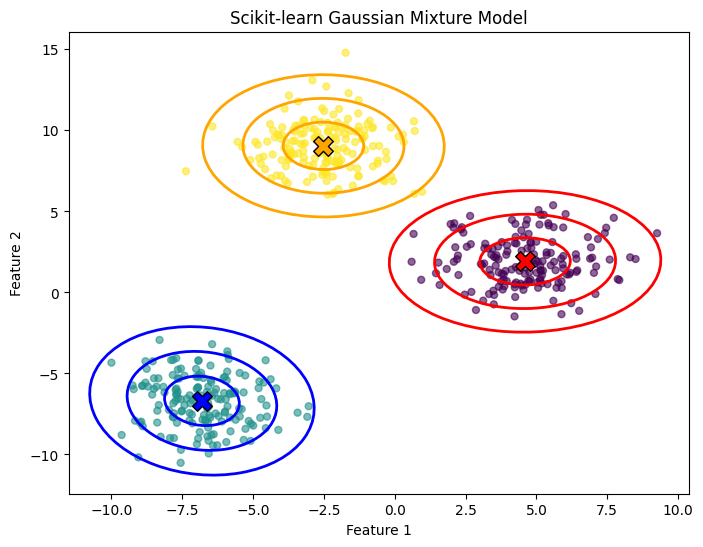

In [21]:
plot_gmm(
    X,
    gmm.means_,
    gmm.covariances_,
    sklearn_responsibilities,
    "Scikit-learn Gaussian Mixture Model"
)

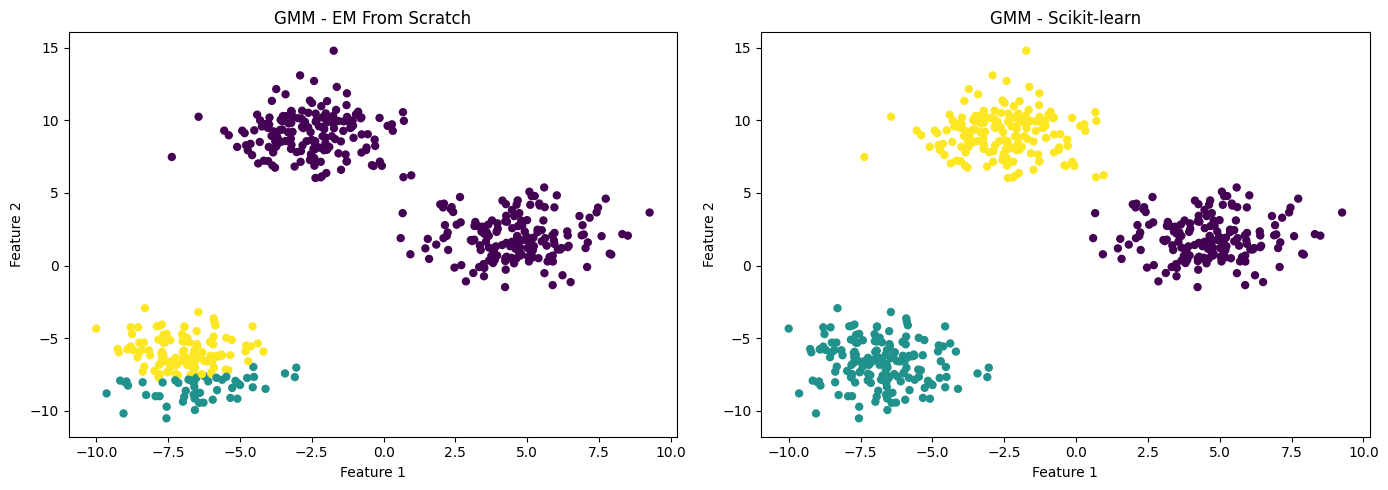

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# EM from scratch
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap='viridis',
    s=25
)

axes[0].set_title("GMM - EM From Scratch")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Scikit-learn
axes[1].scatter(
    X[:, 0],
    X[:, 1],
    c=sklearn_labels,
    cmap='viridis',
    s=25
)

axes[1].set_title("GMM - Scikit-learn")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [23]:
print("========== MODEL COMPARISON ==========")

print("\nCustom EM Algorithm:")
print("Number of Clusters:", len(np.unique(labels)))
print("Cluster Means:\n", means)
print("Cluster Weights:\n", weights)

print("\nScikit-learn GMM:")
print("Number of Clusters:", len(np.unique(sklearn_labels)))
print("Cluster Means:\n", gmm.means_)
print("Cluster Weights:\n", gmm.weights_)

print("\nLog Likelihood:", gmm.score(X) * len(X))
print("AIC:", gmm.aic(X))
print("BIC:", gmm.bic(X))
print("Converged:", gmm.converged_)

========== MODEL COMPARISON ==========

Custom EM Algorithm:
Number of Clusters: 3
Cluster Means:
 [[ 1.04292437  5.47821287]
 [-6.39979808 -8.23114247]
 [-6.98506451 -6.02291433]]
Cluster Weights:
 [0.66799997 0.10101711 0.23098289]

Scikit-learn GMM:
Number of Clusters: 3
Cluster Means:
 [[ 4.59818777  1.91478415]
 [-6.80698643 -6.69480836]
 [-2.51823554  9.04755181]]
Cluster Weights:
 [0.33427674 0.332      0.33372326]

Log Likelihood: -2346.5942499814805
AIC: 4727.188499962961
BIC: 4798.836837636139
Converged: True
